In [1]:
from ModelSimlink import RadiativeTransitions, Levels
from standard_imports import *
from loaders import index
from plots import adv_plt, splt, interactive
from scipy.optimize import curve_fit
from Tools import LinesFitter

Call %matplotlib widget
Remember to select "cambiare presentazione" -> "application" in the cells output when you want interactive mode


In [2]:
data = index.load_index_and_data( "TestData/RfPen/20230620" ) + index.load_index_and_data( "TestData/PlasmaBIC/20241031" )

Avantes spectrum TestData/RfPen/20230620\New Experiment0005.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0006.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0007.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0008.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0013.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0014.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0015.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0016.Raw8 normalized by a factor of 0.200000 s
8 rows loaded
Avantes spectrum TestData/PlasmaBIC/20241031\101_6us.RAW8 normalized by a factor of 0.400000 s
Avantes spectrum TestData/PlasmaBIC/20241031\102_6us.RAW8 normalized by a f

In [3]:
lf = LinesFitter.LinesFitter( Levels.Levels(), RadiativeTransitions.RadiativeTransitions() )

Initializing class Levels


In [4]:
calib_spectrum = pd.read_csv('CalibrationData/Calib_20250204_FCUVIR600.csv', index_col = False).to_dict('list')

In [5]:
for d in data:
    baseline = np.mean( d['avantes']['int'][:40] )
    d['calib_int'] = ( d['avantes']['int'] - baseline ) * np.interp( d['avantes']['wl'], calib_spectrum['wl'], calib_spectrum['f_normalized'] )

    d['densities'] = lf.summarized_densities( d['avantes']['wl'], d['calib_int'], baseline )

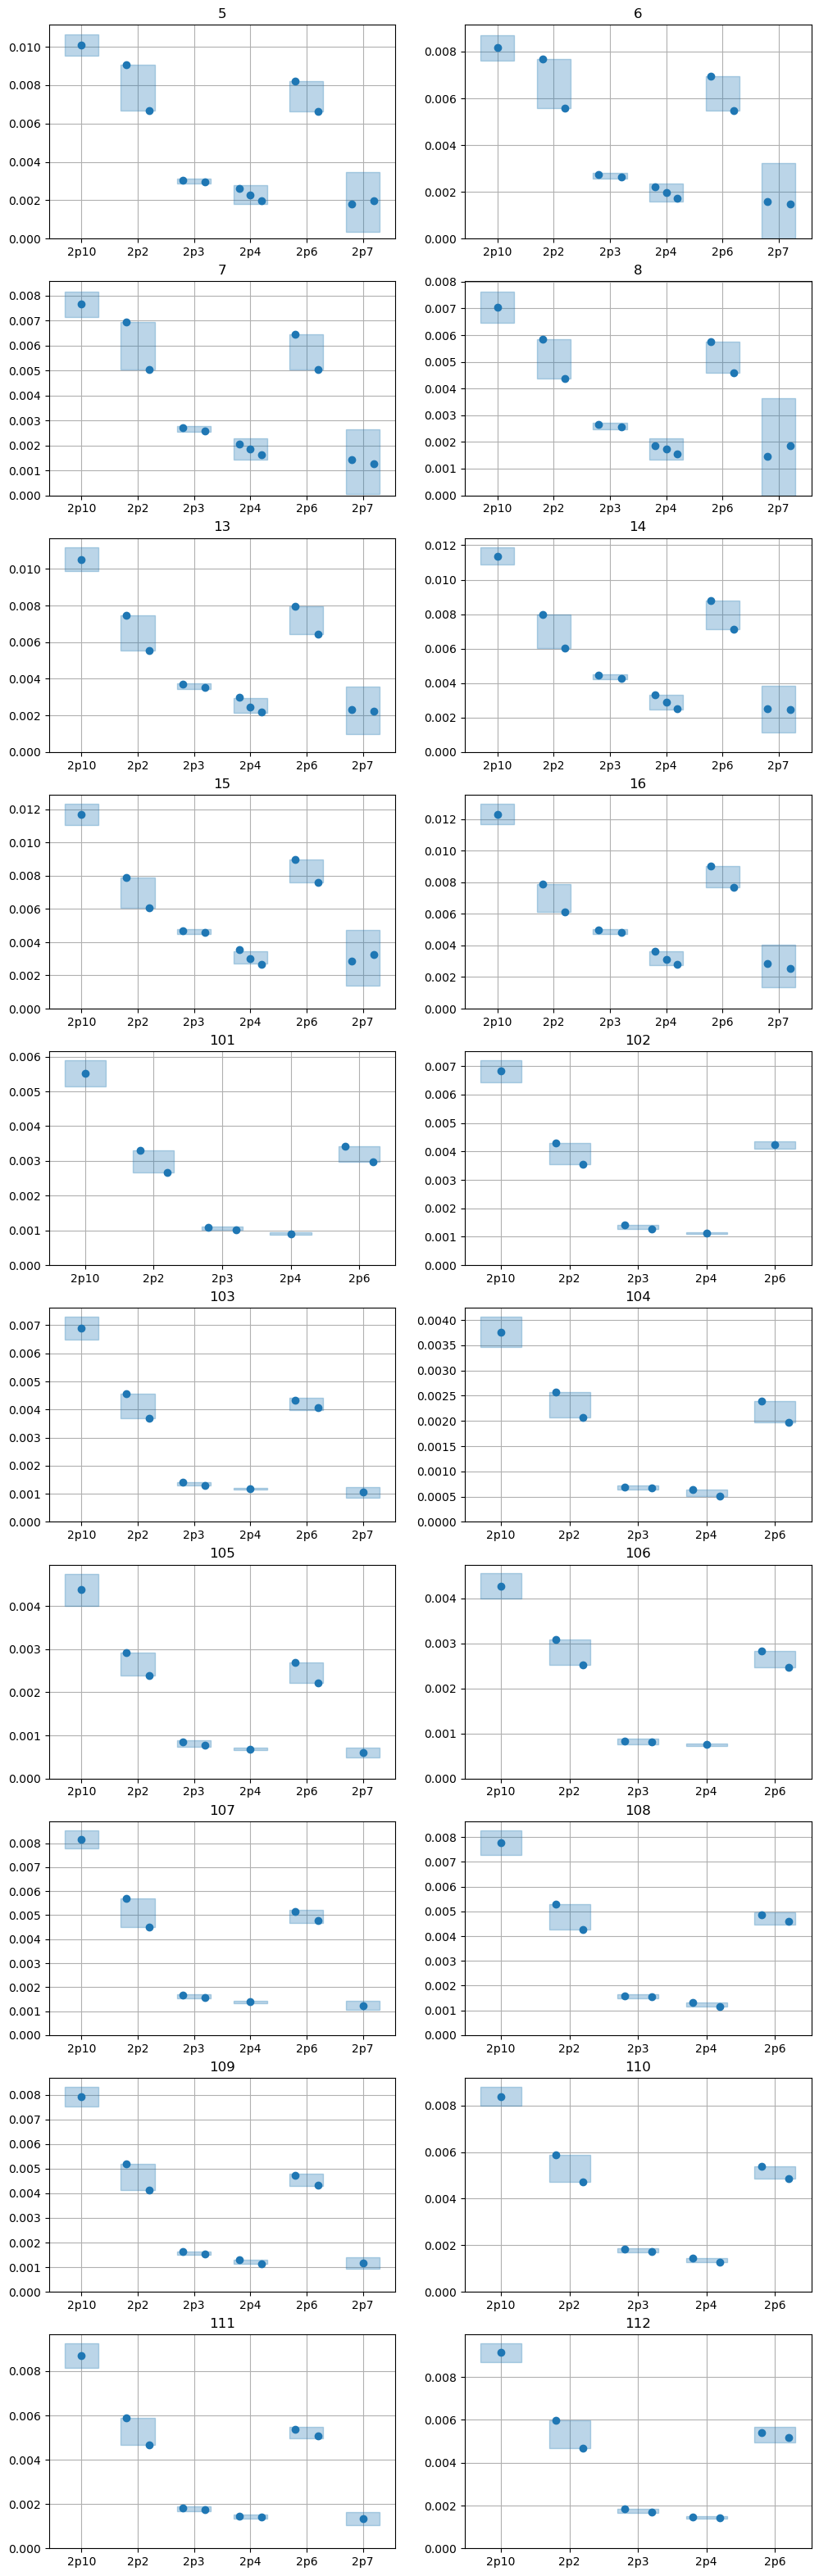

In [6]:
splt.init_bytot( len( data ), cols = 2 )
for d in data:
    splt.next()

    for i, (k,v) in enumerate( d['densities'].items() ):
        plt.fill_between( [ i - 0.3, i + 0.3 ], np.array([1,1]) * v['density_n'] - v['density_s'], np.array([1,1]) * v['density_n'] + v['density_s'], color = 'tab:blue', alpha = 0.3 )
        xs = np.linspace( i - 0.2, i + 0.2, len( v['lines'] ) )
        if( len( v['lines'] ) == 1 ):
            xs = [ i ]
        plt.plot( xs, [ j['density'] for j in v['lines'] ], 'o', color = 'tab:blue' )

    plt.xticks( list( range( len( d['densities'].keys() ) ) ), list( d['densities'].keys() ) )
    plt.ylim( bottom = 0 )

    plt.title(d['ID'])